# Лабораторная работа №3 — Регрессия

Credit Risk Dataset. Ноутбук содержит вычислительный код и сохранённые результаты эксперимента. Выполняйте ячейки сверху вниз. По умолчанию показываются ранее рассчитанные результаты; для повторного обучения установите `REBUILD = True` (расчёт может занять несколько минут).

In [2]:
from pathlib import Path
import sys, os, json
import pandas as pd
from IPython.display import display, Image, Markdown

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/credit_risk_dataset.csv').exists()), None)
if PROJECT is None:
    raise RuntimeError('Откройте ноутбук из папки проекта ОМО')
LAB = PROJECT / 'Лаба3'
sys.path.insert(0, str(LAB))
REBUILD = False


## Данные и очистка
Одна строка — кредит. Удаляем строки с пропусками и полные дубликаты. В моделях масштабирование и кодирование выполняются отдельно от этой демонстрации.

In [4]:
raw = pd.read_csv(PROJECT / 'data/raw/credit_risk_dataset.csv')
display(raw.head())
display(raw.isna().sum().rename('Пропуски').to_frame())
clean = raw.dropna().drop_duplicates()
print(f'Исходных строк: {len(raw)}; после очистки: {len(clean)}')


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


,Пропуски
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


Исходных строк: 32581; после очистки: 28501


## Подготовка моделей
Цель — loan_int_rate; loan_status исключён. Разделение 80/20. StandardScaler и OneHotEncoder входят в Pipeline. Параметры LASSO и Ridge выбираются по RMSE на пяти фолдах.

In [6]:
__file__ = str(LAB / 'regression.py')
"""Лабораторная №3: прогноз процентной ставки. python Лаба3/regression.py."""

import os
from pathlib import Path
import json
import platform

ROOT = Path(__file__).resolve().parent
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
os.environ.setdefault("OMP_NUM_THREADS", "2")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "loan_int_rate"
NUMERIC = ["person_age", "person_income", "person_emp_length", "loan_amnt",
           "loan_percent_income", "cb_person_cred_hist_length"]
OUTPUT = ROOT / "reports"


def save(name):
    plt.tight_layout()
    plt.savefig(OUTPUT / name, dpi=150, bbox_inches="tight")
    plt.close()


def make_pipeline(model, categories):
    transform = ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC),
        # Базовая категория исключена: устраняем зависимость dummy-столбцов.
        ("category", OneHotEncoder(drop="first", handle_unknown="ignore",
                                   sparse_output=False), categories),
    ])
    return Pipeline([("preprocess", transform), ("model", model)])


def visualize(data, stage):
    selected = NUMERIC + [TARGET]
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    for ax, feature in zip(axes.flat, selected):
        sns.histplot(data=data, x=feature, bins=40, ax=ax)
    for ax in list(axes.flat)[len(selected):]:
        ax.set_visible(False)
    save(f"{stage}_histograms.png")
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    for ax, feature in zip(axes, ["loan_amnt", "person_income", "person_age"]):
        sns.scatterplot(data=data, x=feature, y=TARGET, alpha=0.15, s=10, ax=ax)
    save(f"{stage}_scatterplots.png")
    plt.figure(figsize=(11, 6))
    sns.boxplot(data=data, x="loan_grade", y=TARGET, order=list("ABCDEFG"))
    save(f"{stage}_boxplots.png")


def evaluate(actual, predicted):
    return {"MAE": float(mean_absolute_error(actual, predicted)),
            "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
            "R2": float(r2_score(actual, predicted))}



## Обучение и подбор параметров
Ниже приведено тело вычислительной программы, разбитое на последовательные ячейки. При `REBUILD=False` обучение пропускается. Для полного повторного расчёта измените флаг в первой ячейке и выполните Restart Kernel and Run All.

In [8]:
if REBUILD:
    OUTPUT.mkdir(parents=True, exist_ok=True)

In [9]:
if REBUILD:
    processed = ROOT / "processed"

In [10]:
if REBUILD:
    processed.mkdir(parents=True, exist_ok=True)

In [11]:
if REBUILD:
    sns.set_theme(style="whitegrid")

In [12]:
if REBUILD:
    raw = pd.read_csv(ROOT.parent / "data/raw/credit_risk_dataset.csv")

In [13]:
if REBUILD:
    complete = raw.dropna()

In [14]:
if REBUILD:
    clean = complete.drop_duplicates()

In [15]:
if REBUILD:
    x = clean.drop(columns=[TARGET, "loan_status"])

In [16]:
if REBUILD:
    y = clean[TARGET]

In [17]:
if REBUILD:
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [18]:
if REBUILD:
    visualize(clean.loc[x_train.index], "train_clean")

In [19]:
if REBUILD:
    visualize(raw, "raw")

In [20]:
if REBUILD:
    categories = [name for name in x if name not in NUMERIC]

In [21]:
if REBUILD:
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [22]:
if REBUILD:
    models = {
        "LinearRegression": (LinearRegression(), {}),
        "LASSO": (Lasso(max_iter=50000), {"model__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10]}),
        "Ridge": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    }

In [23]:
if REBUILD:
    rows, details, coefficients = [], {}, []

In [24]:
if REBUILD:
    predictions = pd.DataFrame({"source_row": x_test.index, "actual": y_test.to_numpy()})

In [25]:
if REBUILD:
    fig_predictions, axes_predictions = plt.subplots(1, 3, figsize=(17, 5))

In [26]:
if REBUILD:
    fig_residuals, axes_residuals = plt.subplots(1, 3, figsize=(17, 5))

In [27]:
if REBUILD:
    fig_hist, axes_hist = plt.subplots(1, 3, figsize=(17, 5))

In [28]:
if REBUILD:
    baseline = DummyRegressor(strategy="mean").fit(x_train, y_train)

In [29]:
if REBUILD:
    baseline_metrics = evaluate(y_test, baseline.predict(x_test))

In [30]:
if REBUILD:
    final_pipeline = None

In [31]:
if REBUILD:
    for ax_p, ax_r, ax_h, (name, (model, grid)) in zip(
            axes_predictions, axes_residuals, axes_hist, models.items()):
        print(f"Training {name}...", flush=True)
        search = GridSearchCV(make_pipeline(model, categories), grid, cv=cv,
                              scoring="neg_root_mean_squared_error", n_jobs=2, error_score="raise")
        search.fit(x_train, y_train)
        best = search.best_estimator_
        predicted = best.predict(x_test)
        residual = y_test.to_numpy() - predicted
        row = {"model": name, "CV_RMSE": float(-search.best_score_), **evaluate(y_test, predicted)}
        row["train_RMSE"] = evaluate(y_train, best.predict(x_train))["RMSE"]
        rows.append(row)
        predictions[name] = predicted
        details[name] = {"best_parameters": search.best_params_,
                         "intercept": float(best.named_steps["model"].intercept_),
                         "iterations": int(best.named_steps["model"].n_iter_) if name == "LASSO" else None}
        pd.DataFrame(search.cv_results_).to_csv(OUTPUT / f"{name}_cv.csv", index=False)
        coefficients.append(pd.DataFrame({"model": name,
            "feature": best.named_steps["preprocess"].get_feature_names_out(),
            "coefficient": best.named_steps["model"].coef_}))
        ax_p.scatter(y_test, predicted, alpha=0.15, s=10)
        bounds = [min(y_test.min(), predicted.min()), max(y_test.max(), predicted.max())]
        ax_p.plot(bounds, bounds, "r--")
        ax_p.set(xlabel="Actual interest rate (%)", ylabel="Predicted interest rate (%)", title=name)
        ax_r.scatter(predicted, residual, alpha=0.15, s=10)
        ax_r.axhline(0, color="red", linestyle="--")
        ax_r.set(xlabel="Predicted interest rate (%)", ylabel="Actual - predicted (pp)", title=name)
        sns.histplot(residual, bins=40, ax=ax_h)
        ax_h.set(xlabel="Residual (percentage points)", title=name)
        final_pipeline = best
        print(row, flush=True)

In [32]:
if REBUILD:
    for fig, name in [(fig_predictions, "actual_predicted.png"),
                      (fig_residuals, "residuals.png"), (fig_hist, "residual_histograms.png")]:
        plt.figure(fig.number)
        save(name)

In [33]:
if REBUILD:
    coef = pd.concat(coefficients, ignore_index=True)

In [34]:
if REBUILD:
    coef.to_csv(OUTPUT / "coefficients.csv", index=False)

In [35]:
if REBUILD:
    top = coef.groupby("feature").coefficient.apply(lambda s: s.abs().max()).nlargest(12).index

In [36]:
if REBUILD:
    plt.figure(figsize=(13, 9))

In [37]:
if REBUILD:
    sns.barplot(data=coef[coef.feature.isin(top)], x="coefficient", y="feature", hue="model")

In [38]:
if REBUILD:
    save("coefficients.png")

In [39]:
if REBUILD:
    metrics = pd.DataFrame(rows)

In [40]:
if REBUILD:
    metrics.to_csv(OUTPUT / "metrics.csv", index=False)

In [41]:
if REBUILD:
    predictions.to_csv(OUTPUT / "predictions.csv", index=False)

In [42]:
if REBUILD:
    prep = final_pipeline.named_steps["preprocess"]

In [43]:
if REBUILD:
    for name, subset, target in [("train", x_train, y_train), ("test", x_test, y_test)]:
        transformed = pd.DataFrame(prep.transform(subset), columns=prep.get_feature_names_out())
        transformed.insert(0, "source_row", subset.index)
        transformed[TARGET] = target.to_numpy()
        transformed.to_csv(processed / f"{name}_transformed.csv", index=False)

In [44]:
if REBUILD:
    scaler = prep.named_transformers_["numeric"]

In [45]:
if REBUILD:
    winner = metrics.loc[metrics.CV_RMSE.idxmin(), "model"]

In [46]:
if REBUILD:
    details["experiment"] = {
        "target": TARGET, "excluded": ["loan_status"], "original_rows": len(raw),
        "removed_missing": len(raw)-len(complete), "removed_duplicates": len(complete)-len(clean),
        "clean_rows": len(clean), "train_rows": len(x_train), "test_rows": len(x_test),
        "random_state": 42, "selected_by_cv_rmse": winner, "baseline": baseline_metrics,
        "numeric_mean": dict(zip(NUMERIC, scaler.mean_.tolist())),
        "numeric_scale": dict(zip(NUMERIC, scaler.scale_.tolist())),
        "python": platform.python_version(), "sklearn": sklearn.__version__,
        "lasso_zero_coefficients": int((coef.loc[coef.model == "LASSO", "coefficient"] == 0).sum()),
    }

In [47]:
if REBUILD:
    (OUTPUT / "results.json").write_text(json.dumps(details, ensure_ascii=False, indent=2), encoding="utf-8")

In [48]:
if REBUILD:
    print(metrics.to_string(index=False))

In [49]:
if REBUILD:
    print("Selected by CV RMSE:", winner)

## Оценка результатов
Метрики ниже загружаются из сохранённых файлов; после повторного обучения они обновляются.

In [51]:
RESULTS = LAB / 'reports'
display(pd.read_csv(RESULTS / 'metrics.csv'))
display(json.loads((RESULTS / 'results.json').read_text(encoding='utf-8'))) 

,model,CV_RMSE,MAE,RMSE,R2,train_RMSE
0,LinearRegression,1.006876,0.784865,1.000159,0.903575,1.005613
1,LASSO,1.006863,0.784725,1.000096,0.903587,1.005619
2,Ridge,1.006875,0.784813,1.000154,0.903576,1.005614


{'LinearRegression': {'best_parameters': {}, 'intercept': 7.30178376319885, 'iterations': None}, 'LASSO': {'best_parameters': {'model__alpha': 0.0001}, 'intercept': 7.304721987014661, 'iterations': 18}, 'Ridge': {'best_parameters': {'model__alpha': 0.1}, 'intercept': 7.302436724561612, 'iterations': None}, 'experiment': {'target': 'loan_int_rate', 'excluded': ['loan_status'], 'original_rows': 32581, 'removed_missing': 3943, 'removed_duplicates': 137, 'clean_rows': 28501, 'train_rows': 22800, 'test_rows': 5701, 'random_state': 42, 'selected_by_cv_rmse': 'LASSO', 'baseline': {'MAE': 2.689963821905667, 'RMSE': 3.2214902836202244, 'R2': -0.0003818390049465936}, 'numeric_mean': {'person_age': 27.76359649122807, 'person_income': 66504.7875877193, 'person_emp_length': 4.7882456140350875, 'loan_amnt': 9682.538377192983, 'loan_percent_income': 0.16984561403508772, 'cb_person_cred_hist_length': 5.805570175438596}, 'numeric_scale': {'person_age': 6.338872641369004, 'person_income': 52423.07351580

## Графики
Изображения — фактические результаты сохранённого эксперимента.

### actual_predicted

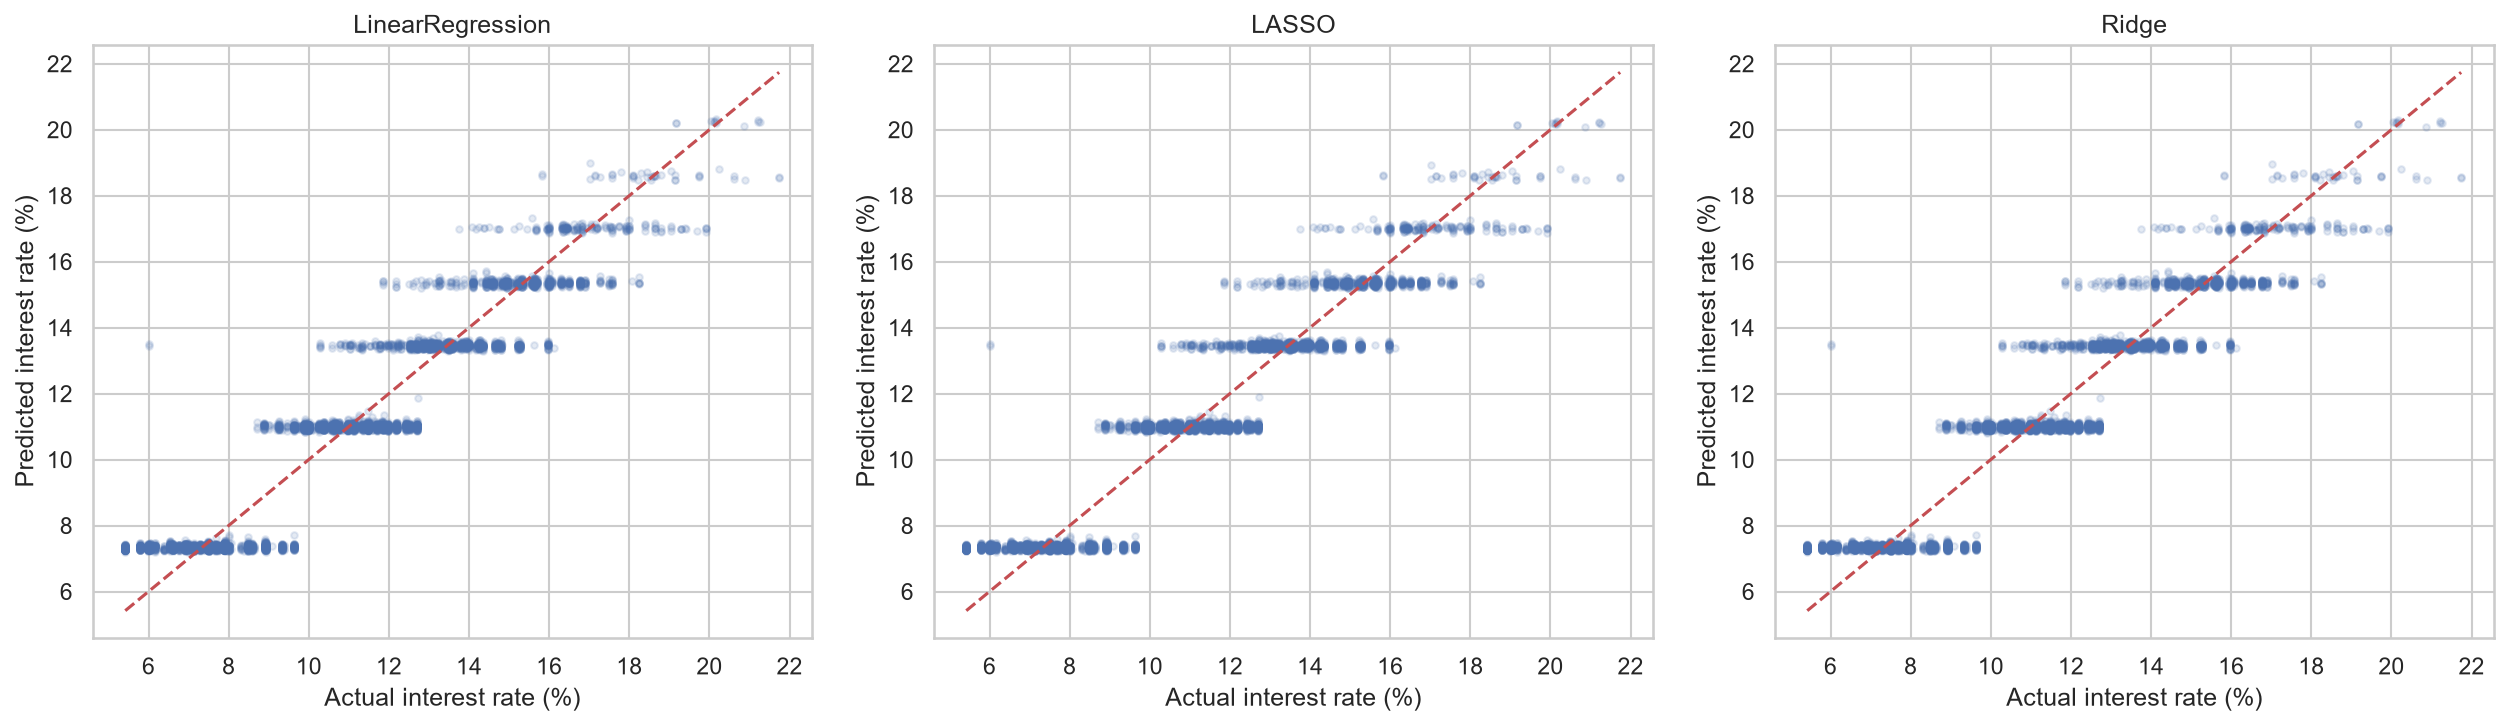

In [54]:
display(Image(filename=str(LAB / 'reports/actual_predicted.png')))

### coefficients

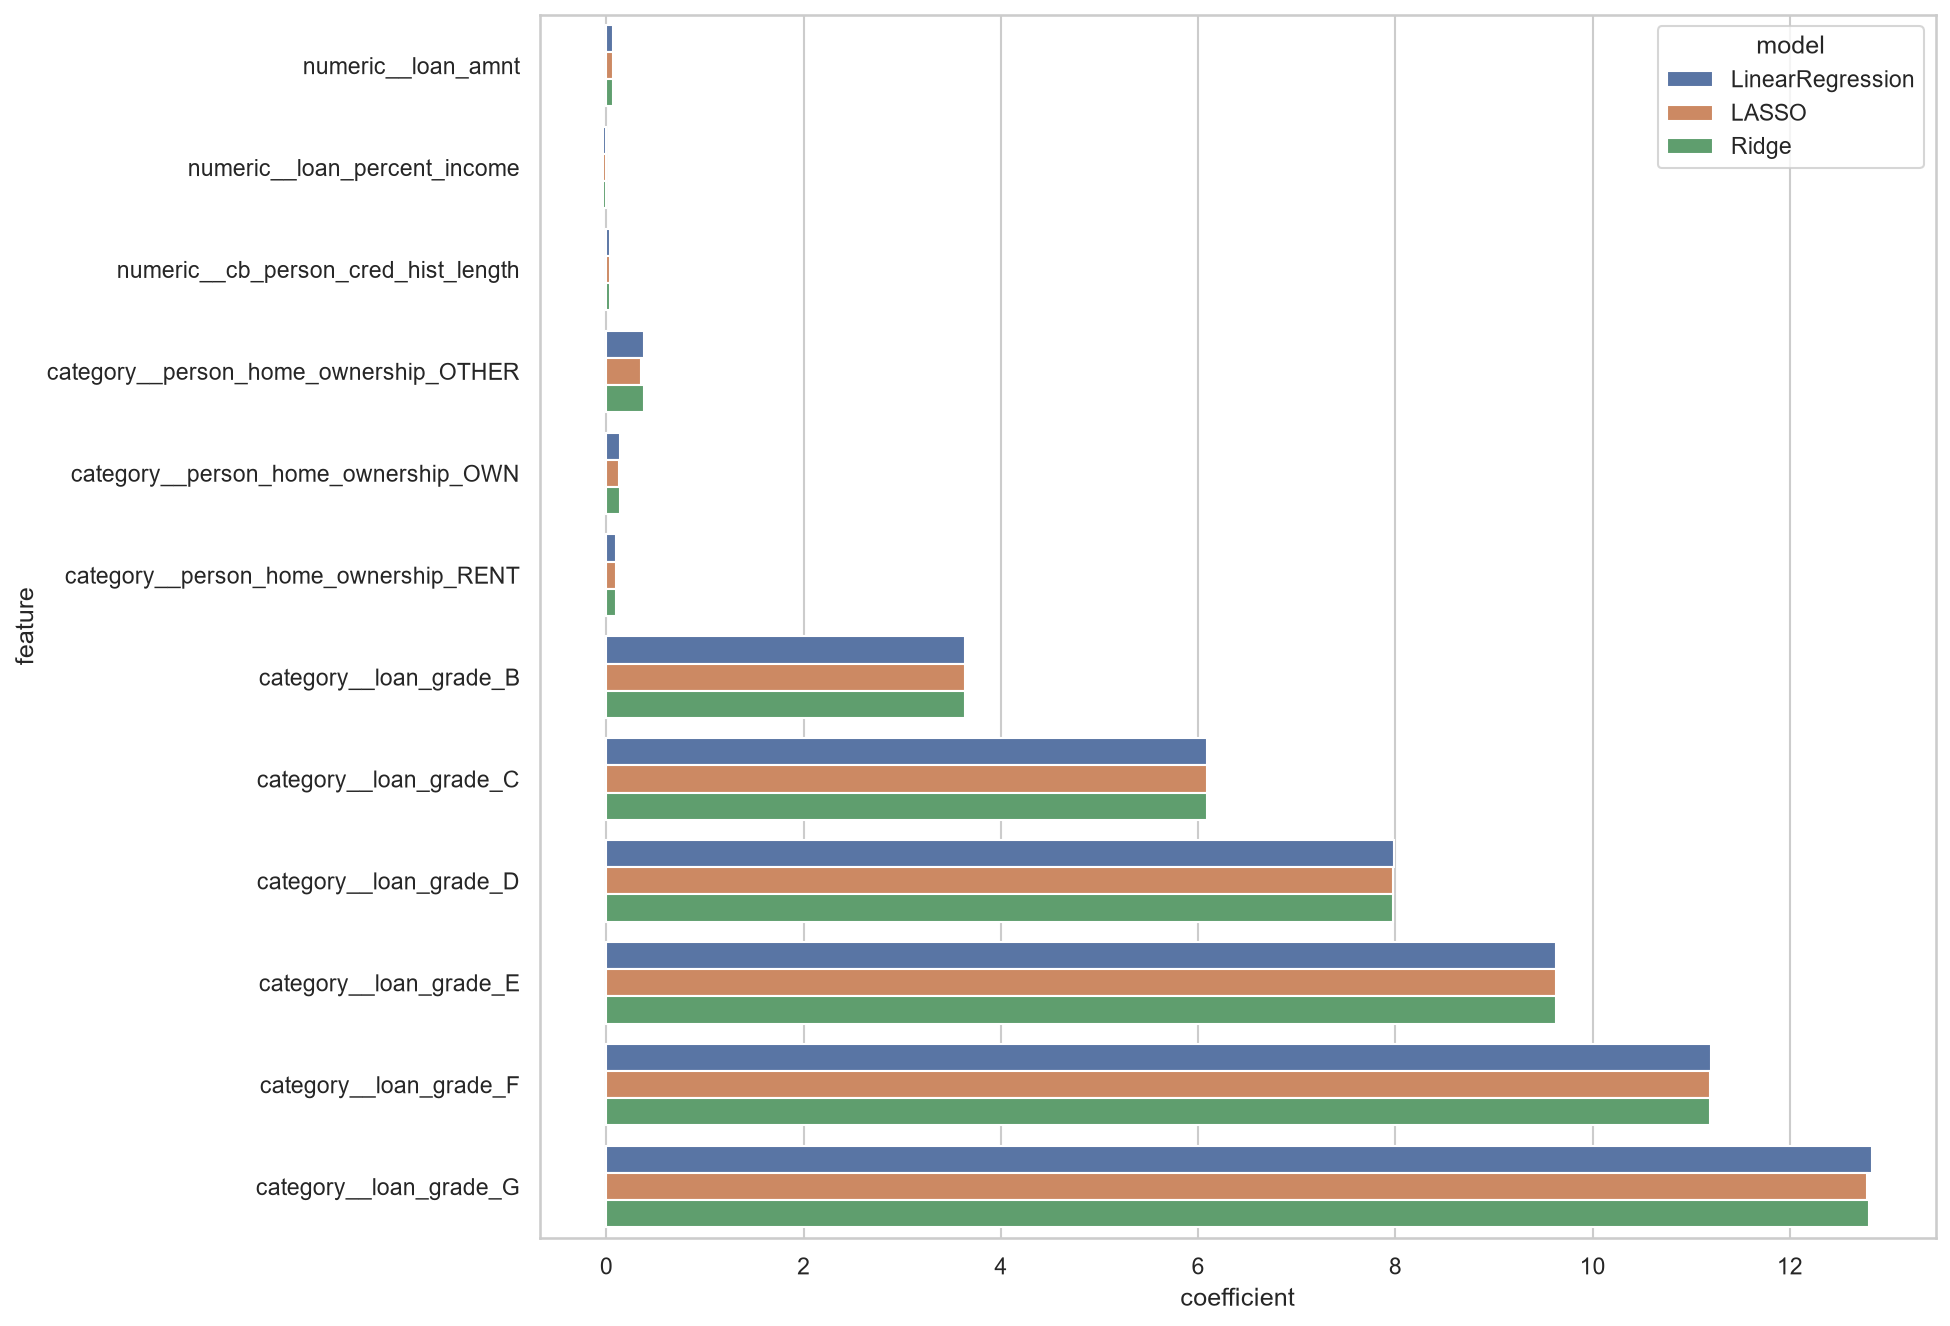

In [56]:
display(Image(filename=str(LAB / 'reports/coefficients.png')))

### raw_boxplots

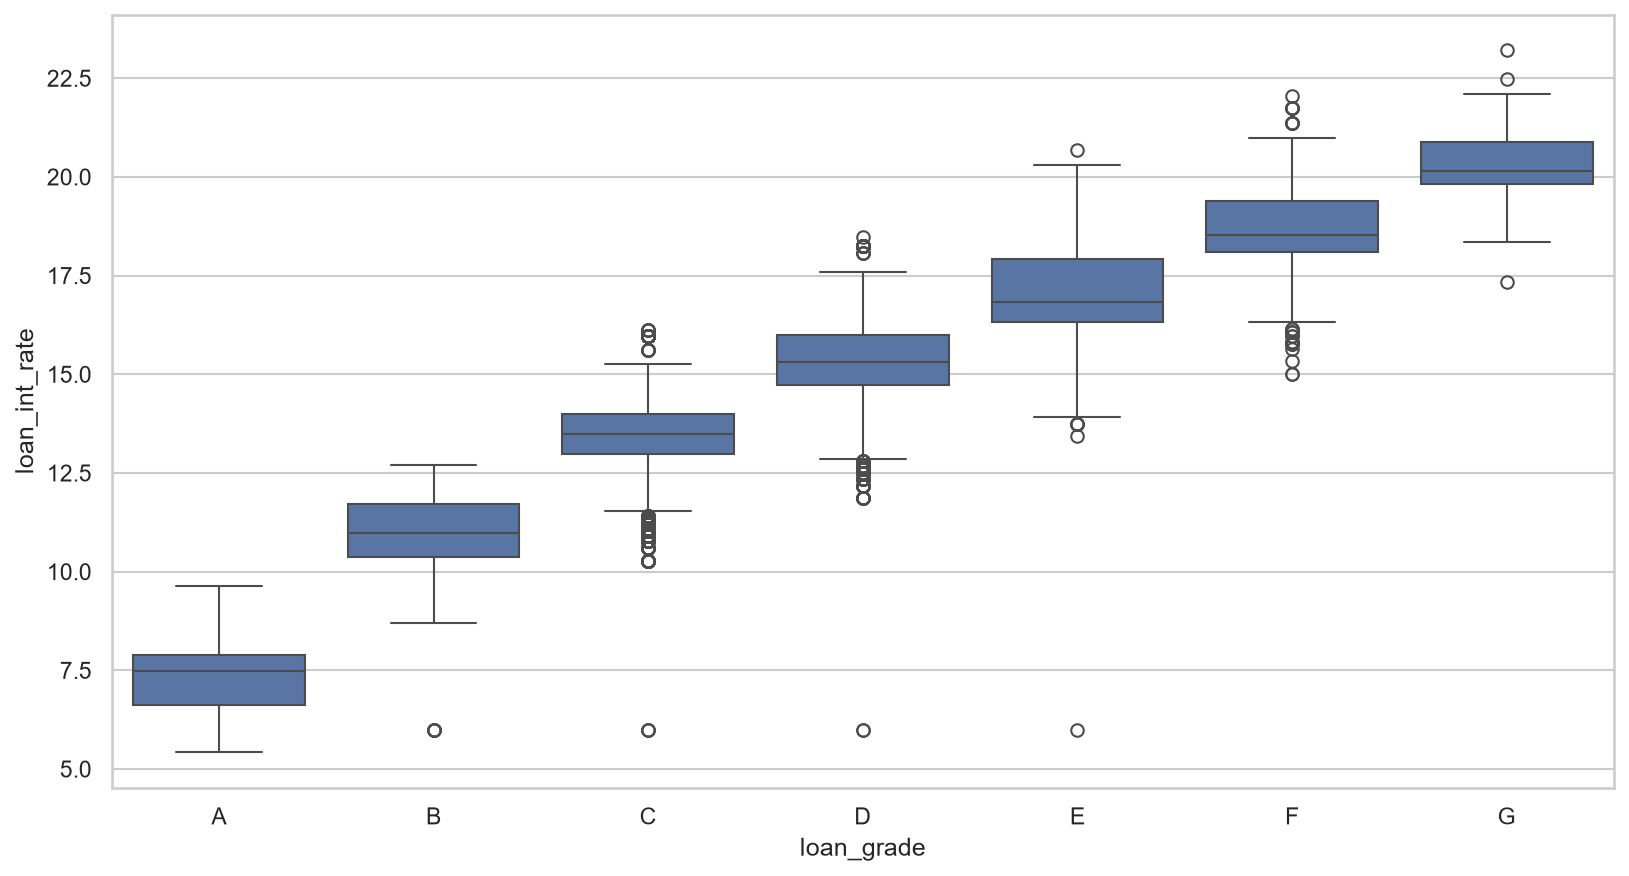

In [58]:
display(Image(filename=str(LAB / 'reports/raw_boxplots.png')))

### raw_histograms

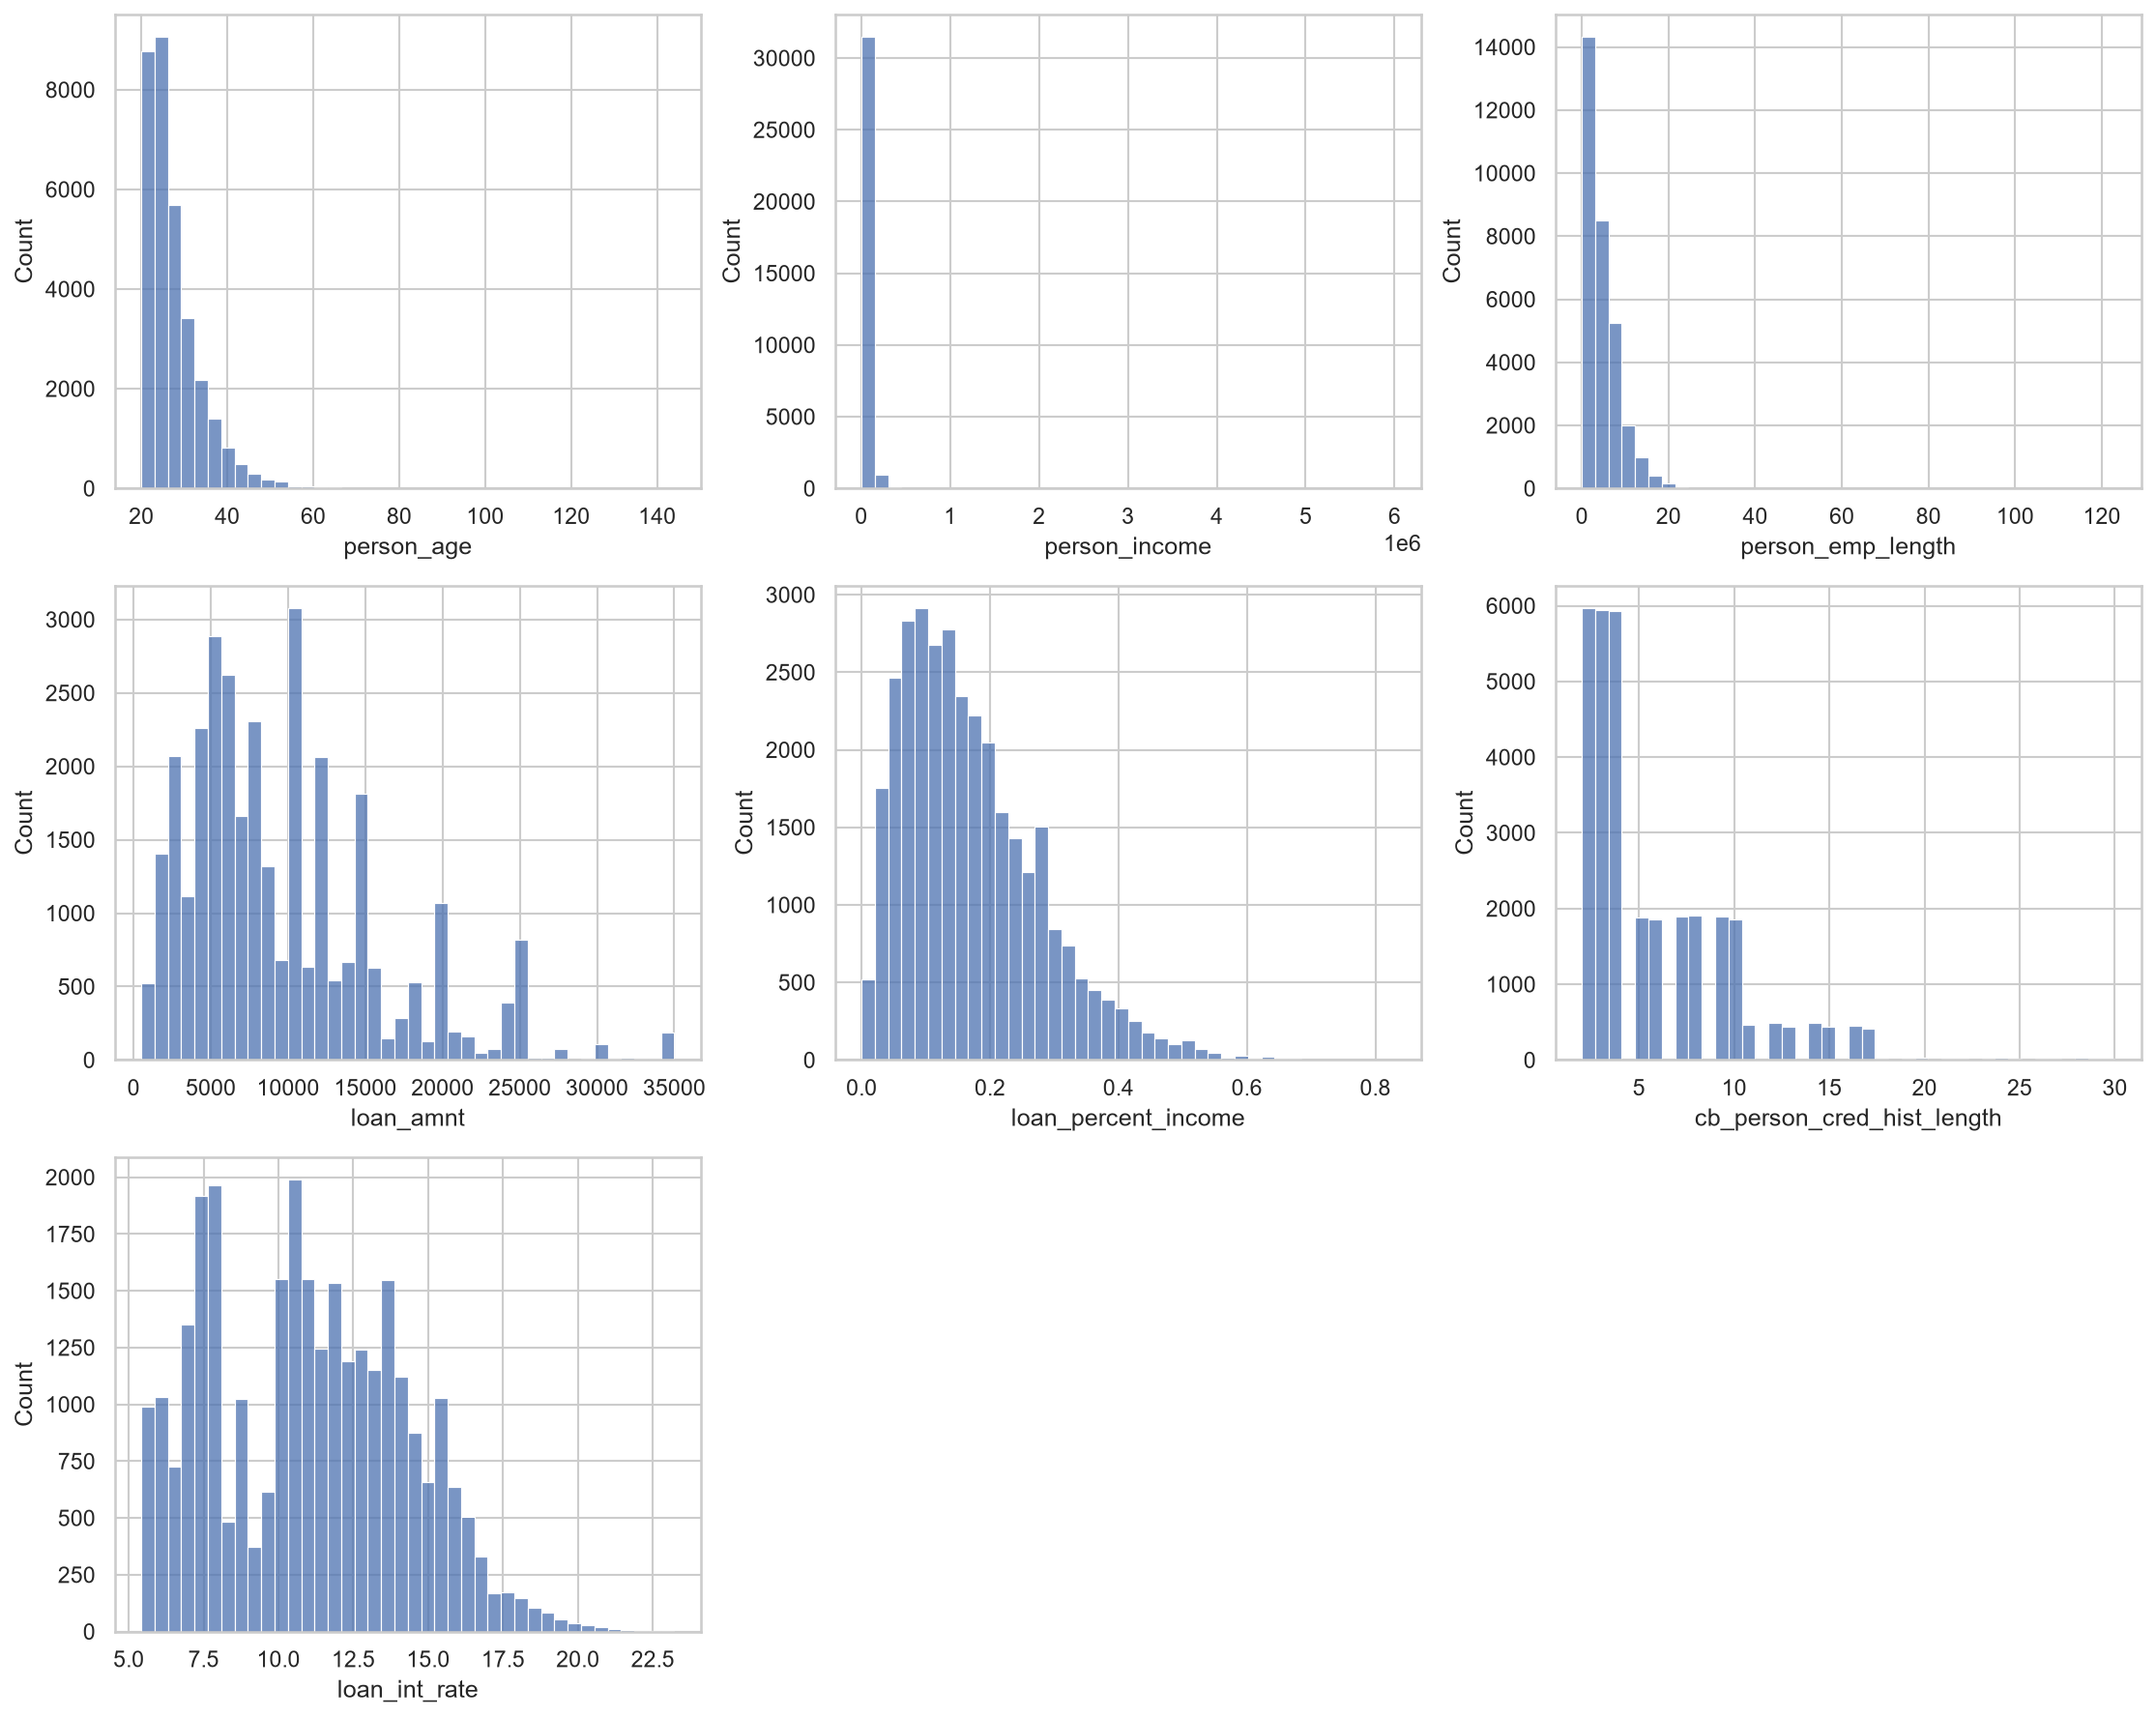

In [60]:
display(Image(filename=str(LAB / 'reports/raw_histograms.png')))

### raw_scatterplots

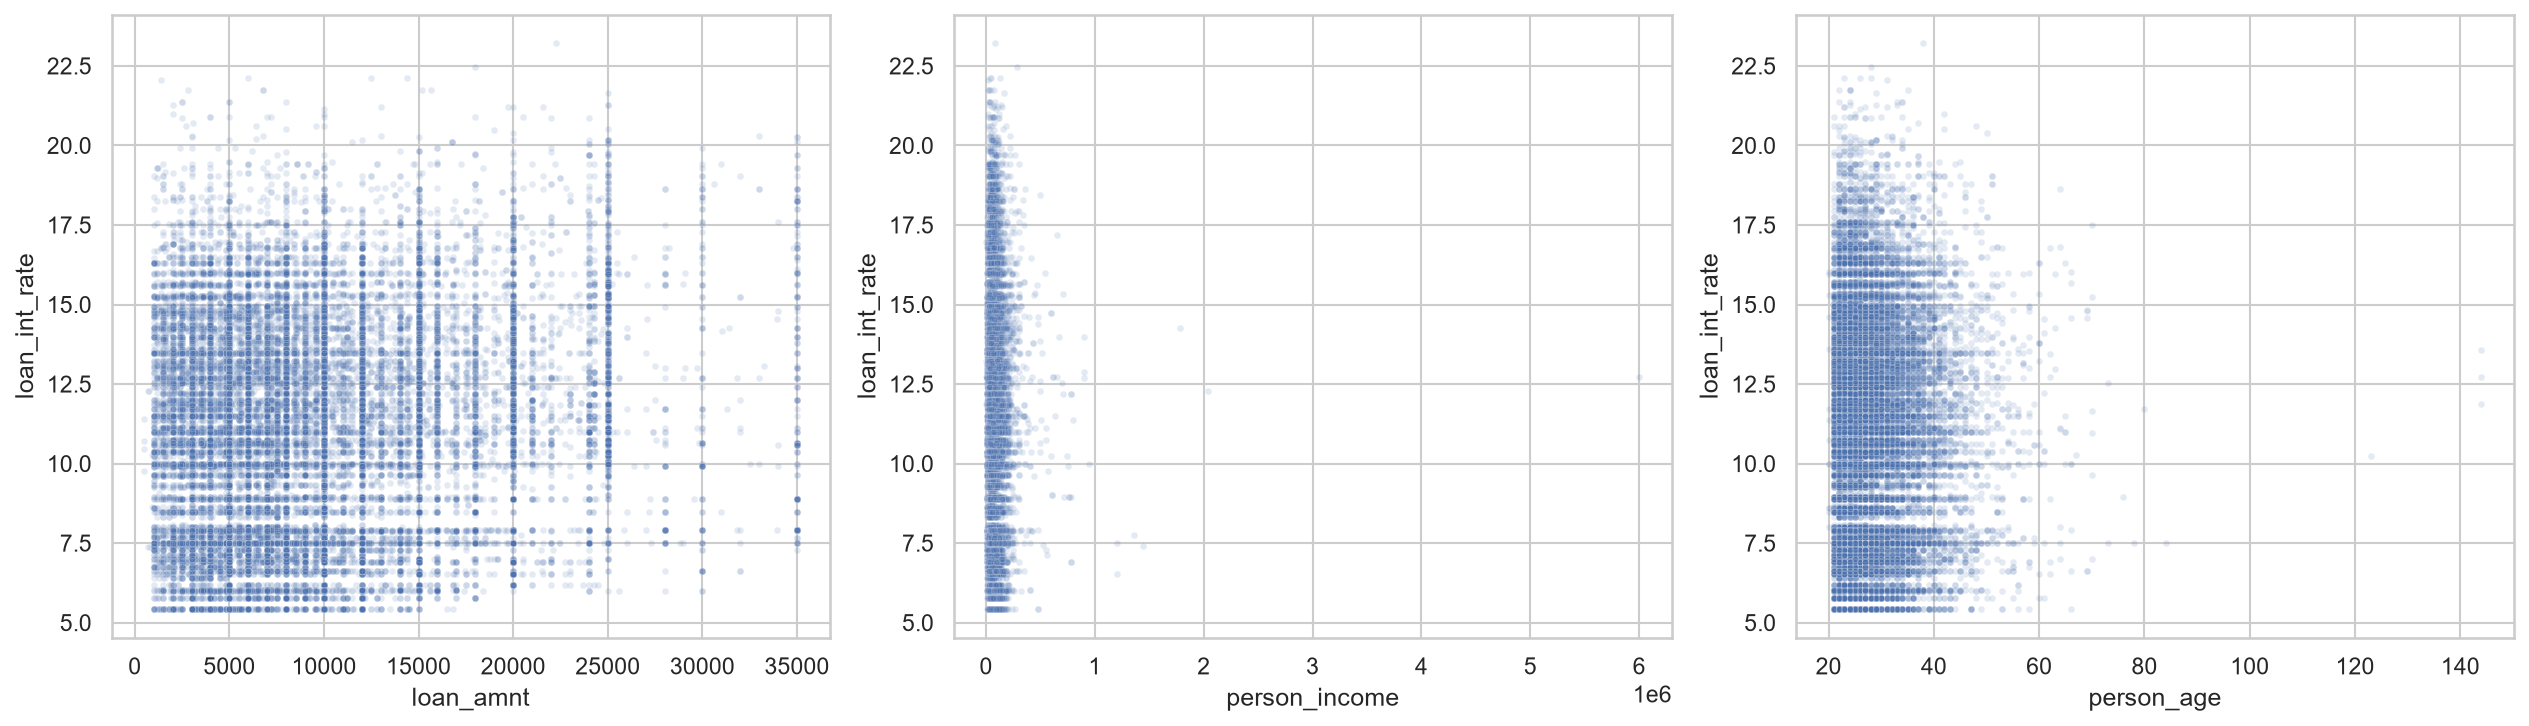

In [62]:
display(Image(filename=str(LAB / 'reports/raw_scatterplots.png')))

### residual_histograms

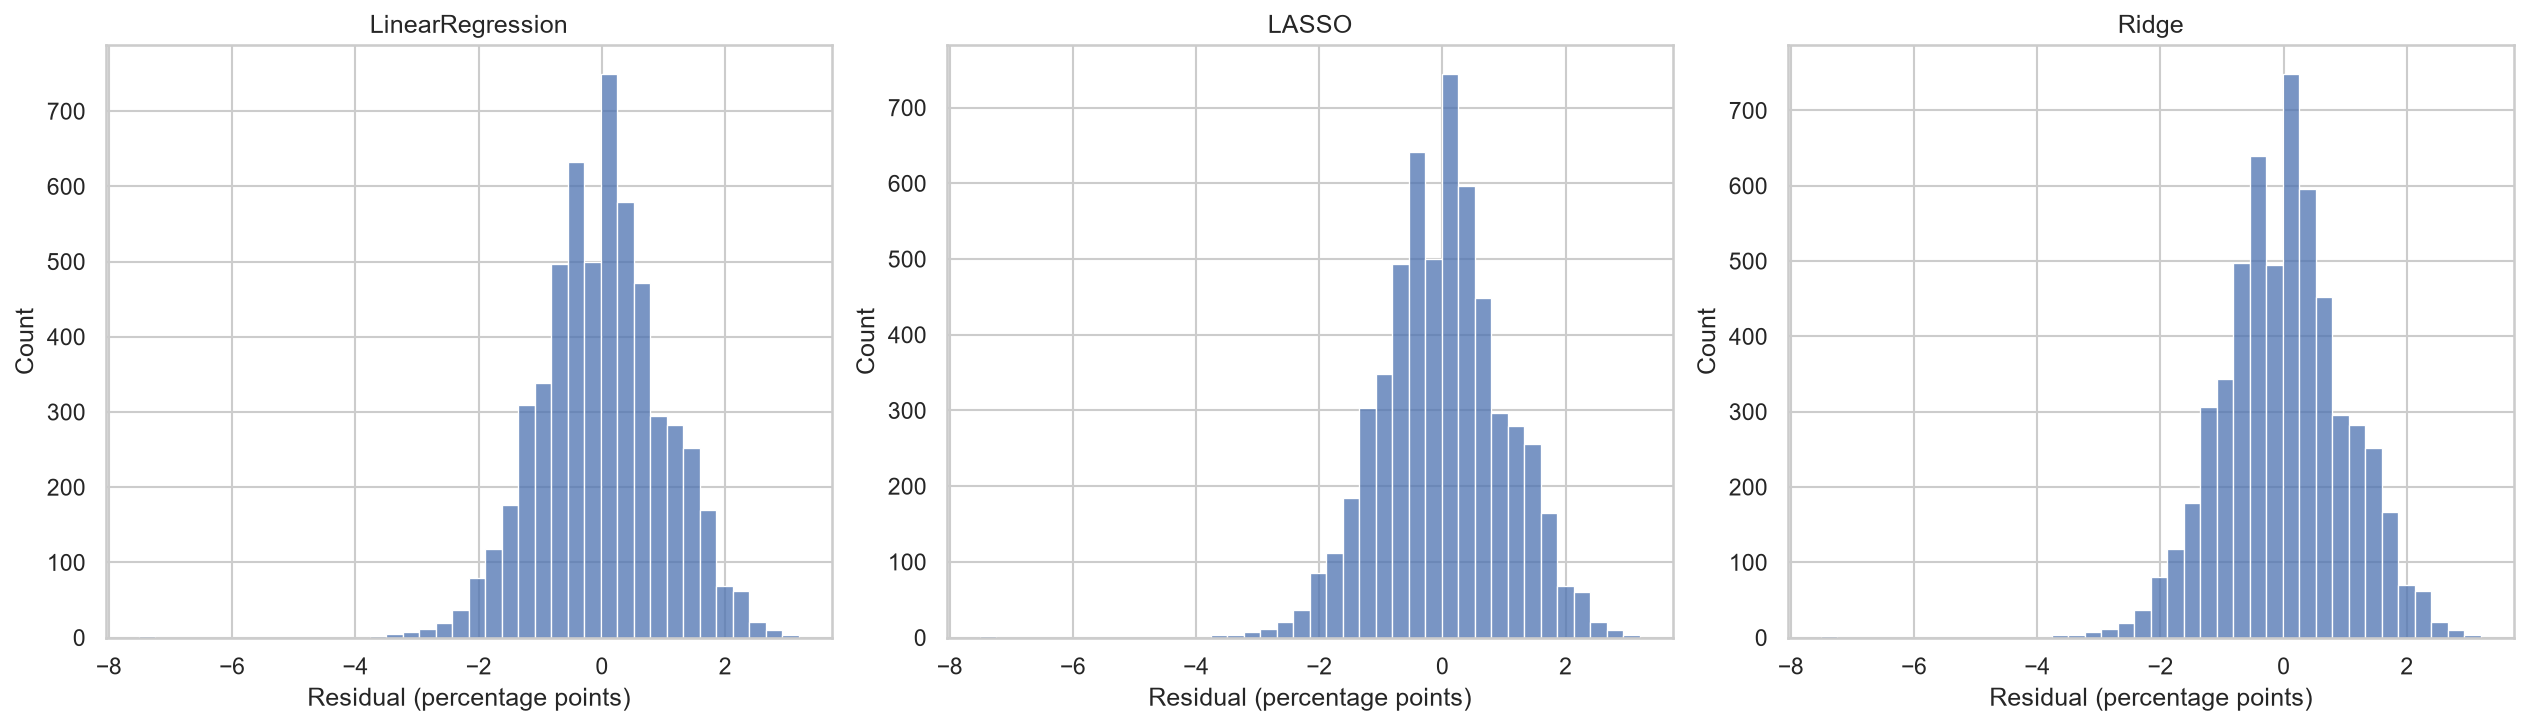

In [64]:
display(Image(filename=str(LAB / 'reports/residual_histograms.png')))

### residuals

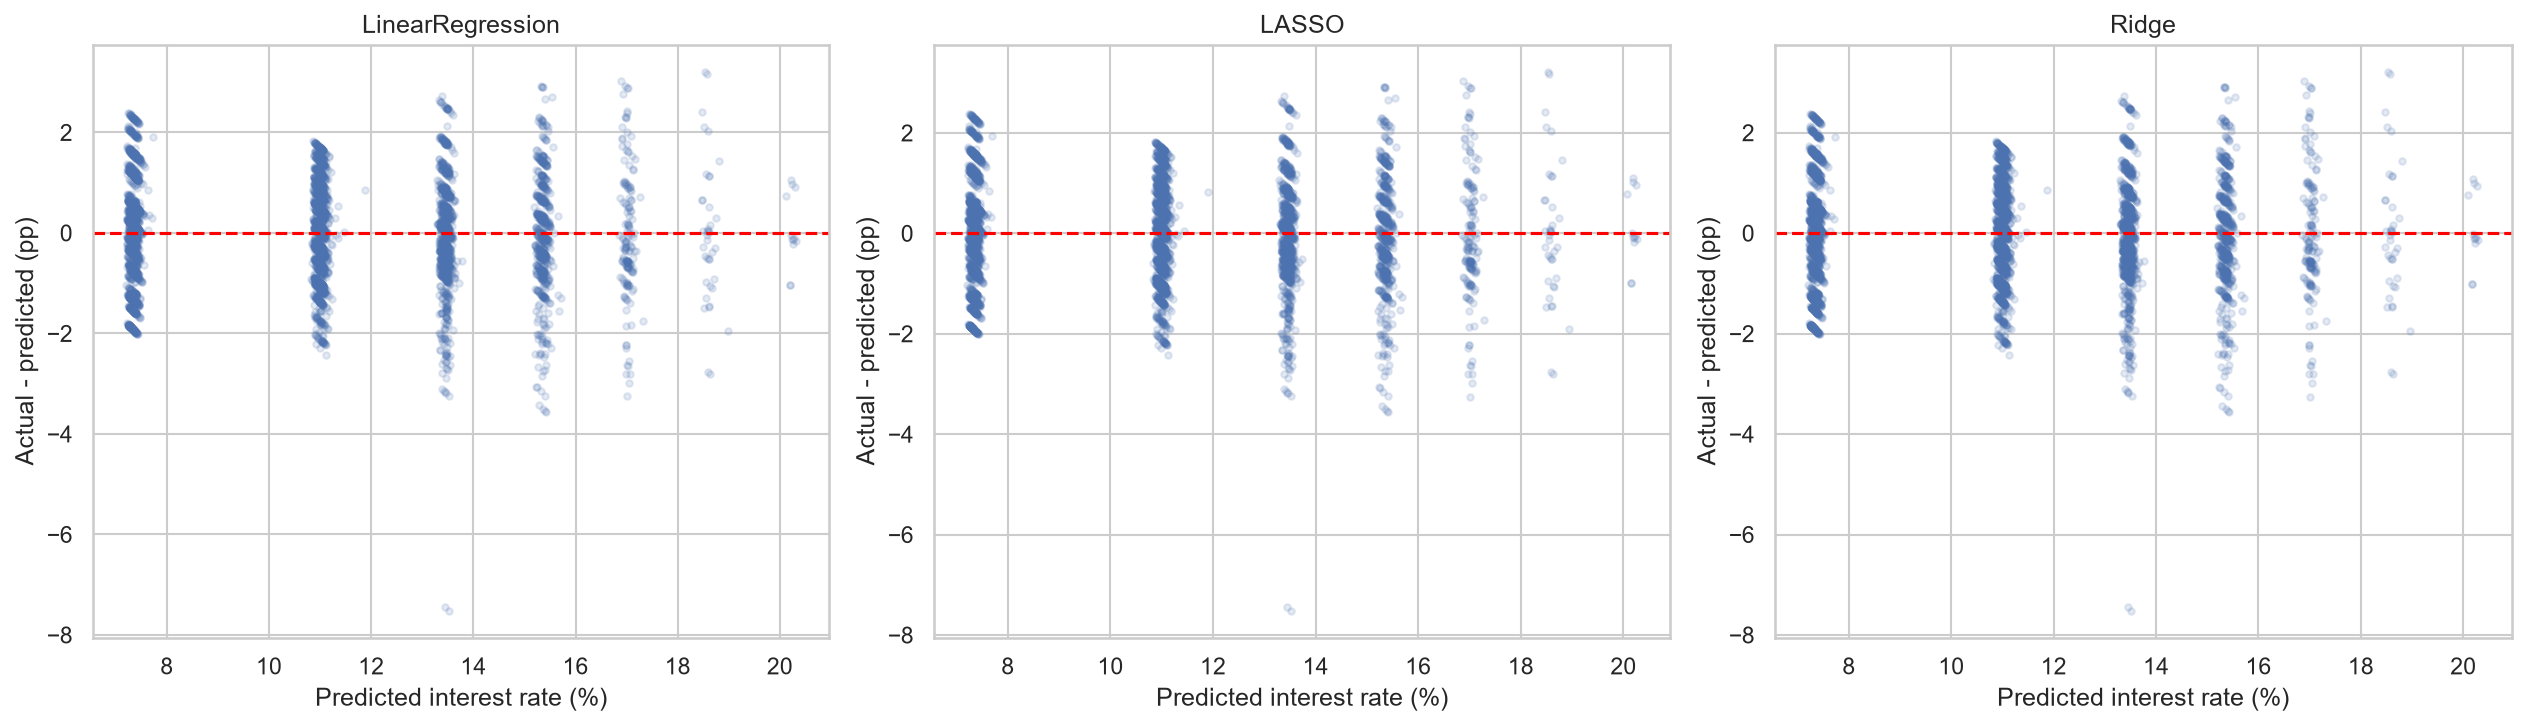

In [66]:
display(Image(filename=str(LAB / 'reports/residuals.png')))

### train_clean_boxplots

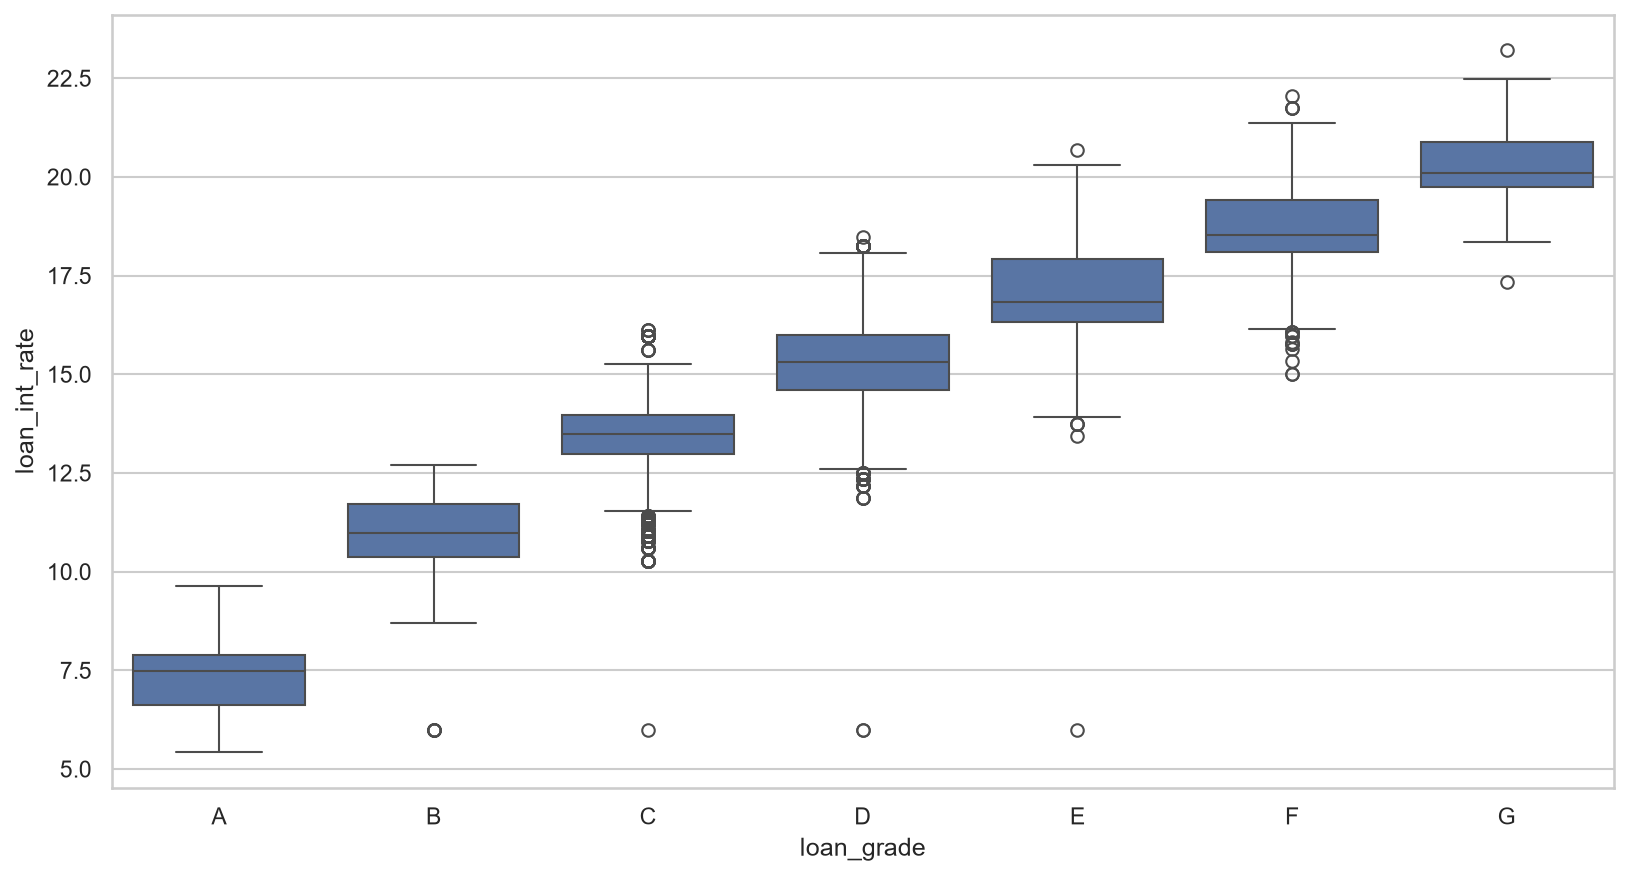

In [68]:
display(Image(filename=str(LAB / 'reports/train_clean_boxplots.png')))

### train_clean_histograms

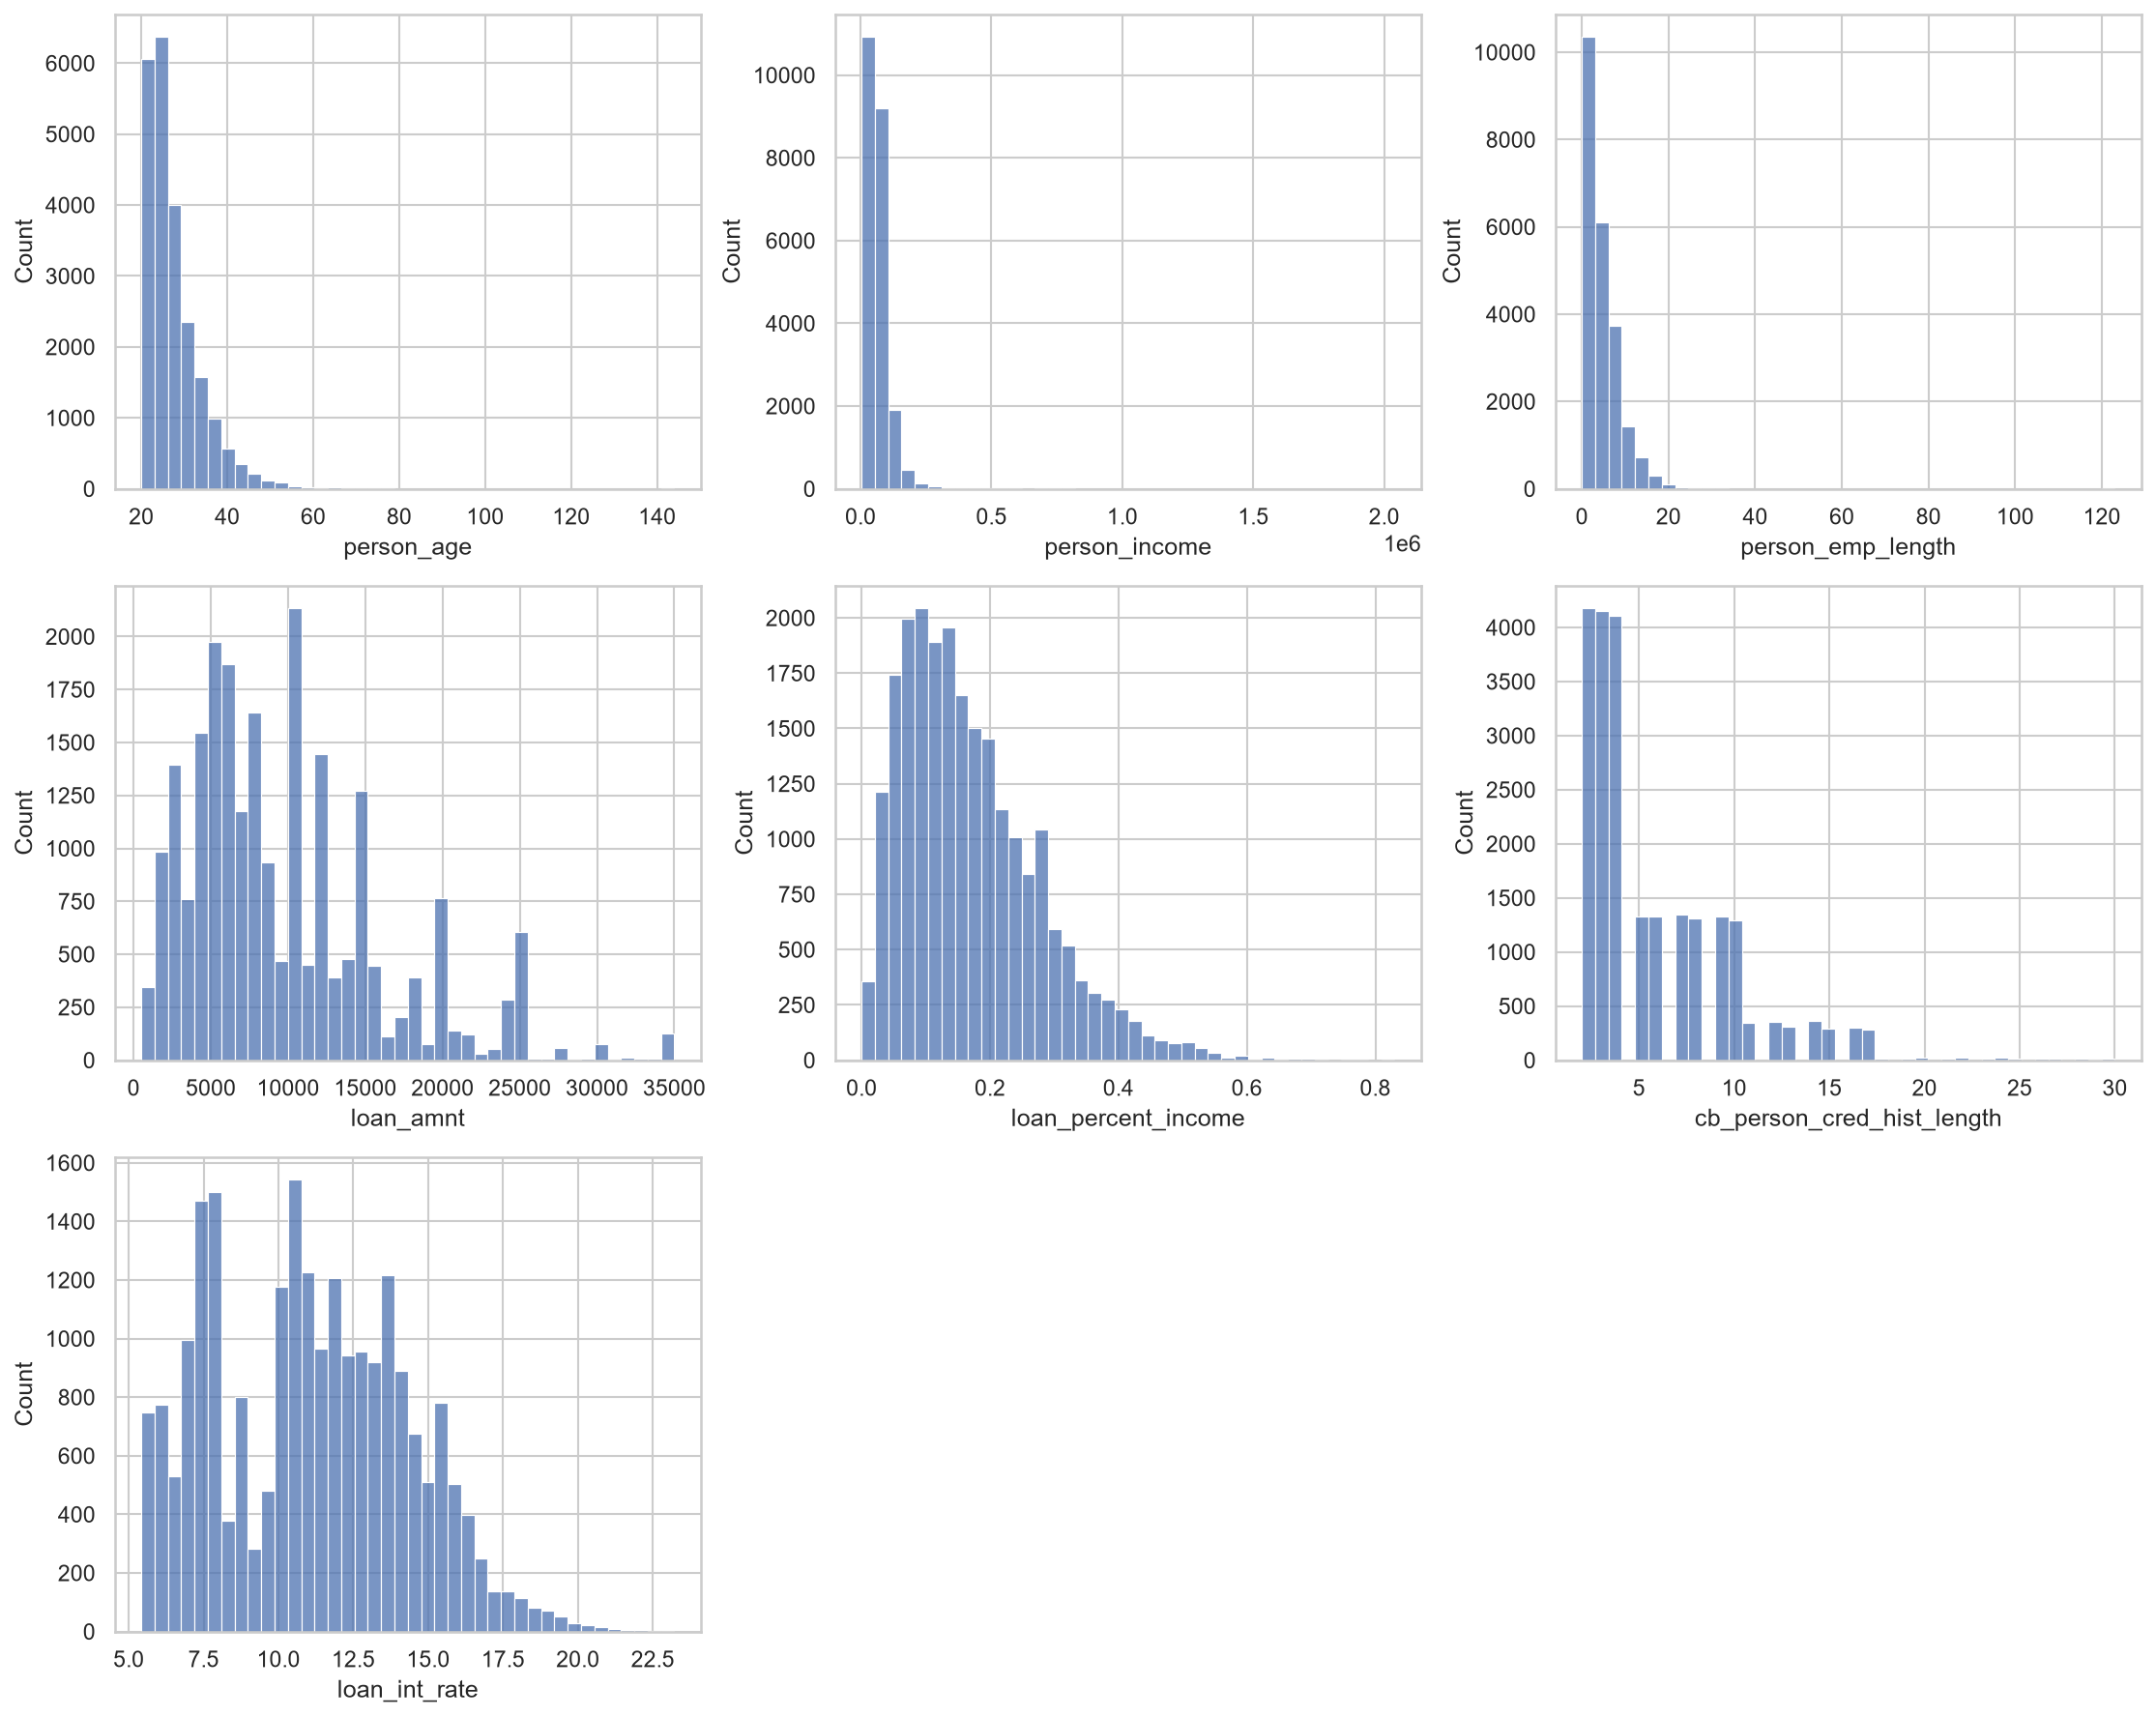

In [70]:
display(Image(filename=str(LAB / 'reports/train_clean_histograms.png')))

### train_clean_scatterplots

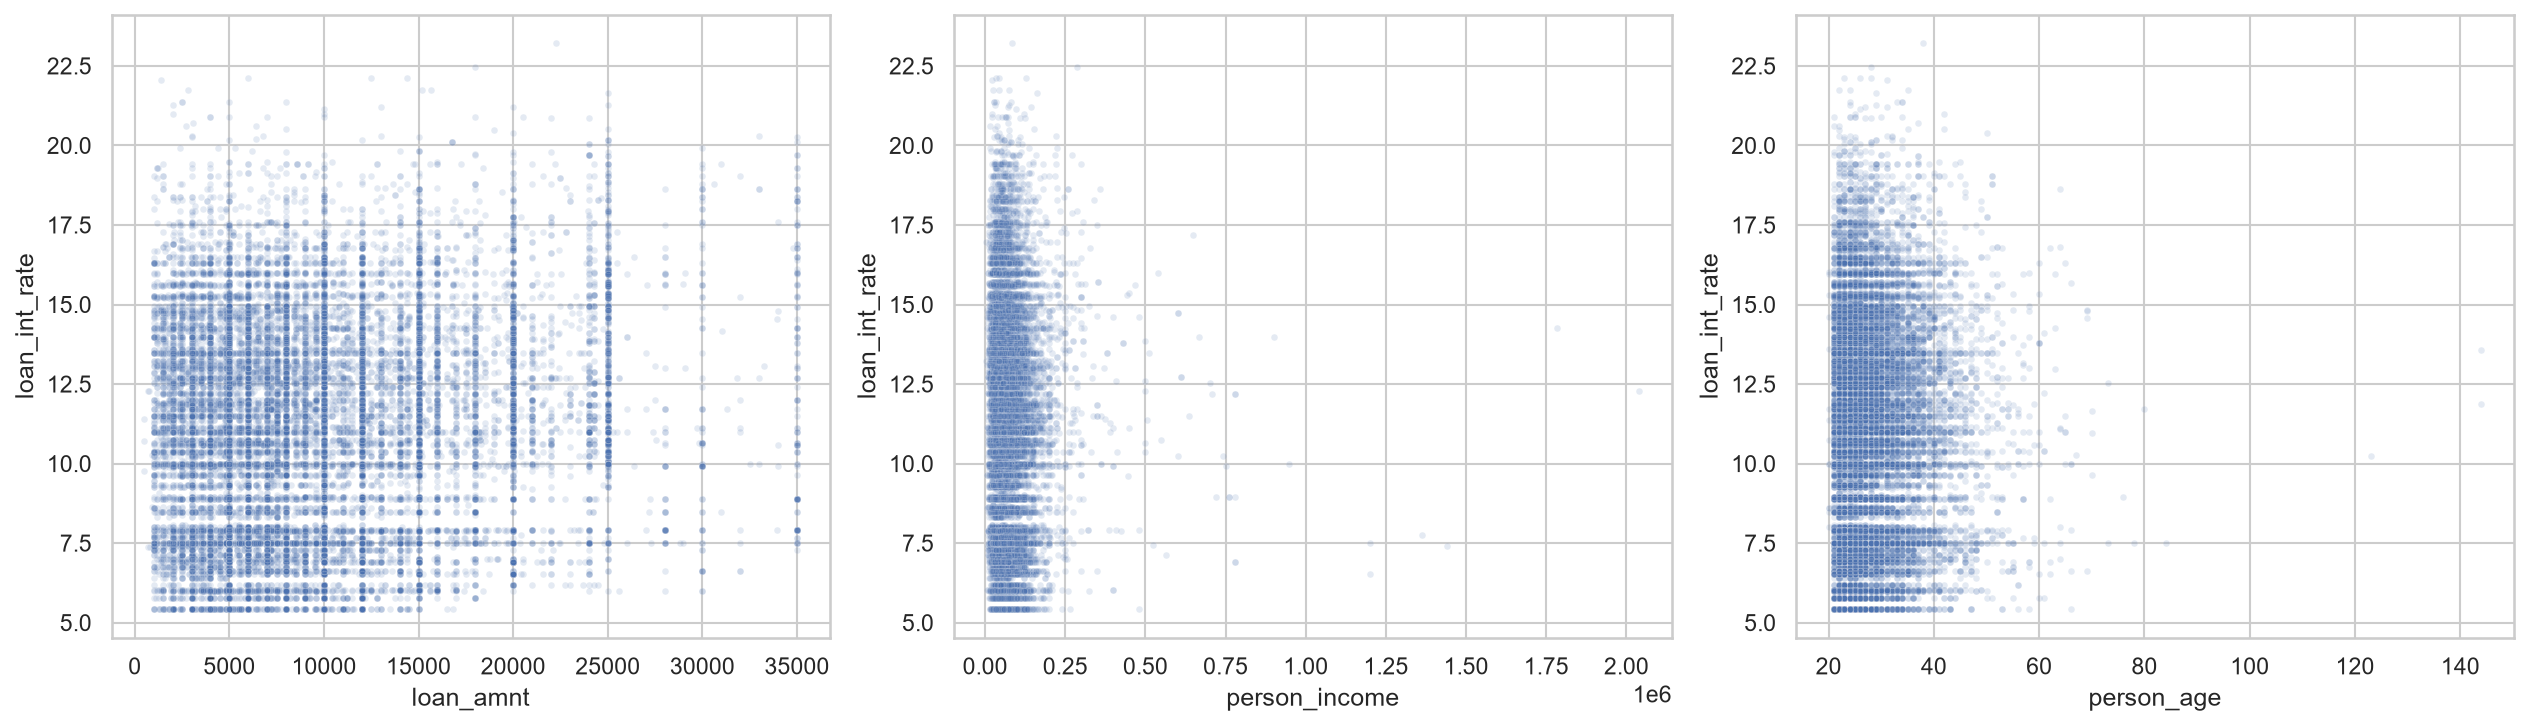

In [72]:
display(Image(filename=str(LAB / 'reports/train_clean_scatterplots.png')))

## Вывод
Все модели практически равны: RMSE ≈ 1 процентного пункта, R² ≈ 0.904. По CV немного лучше LASSO. Результат предполагает известную loan_grade; LASSO не обнулила коэффициенты.

Ограничения: сохранены аномалии; оценка относится к данному эксперименту и не доказывает переносимость на другие данные.